# Joint Fermi-LAT and H.E.S.S. analysis : Source detection

In [1]:
import time
from astropy.coordinates import SkyCoord
from astropy.table import Table, vstack, unique
import astropy.units as u
import matplotlib.pyplot as plt 
import numpy as np 

from gammapy.maps import Map, MapCoord
from gammapy.datasets import Datasets
from gammapy.modeling.models import Models, PointSpatialModel, PowerLawSpectralModel, SkyModel, LogParabolaSpectralModel, GeneralizedGaussianSpatialModel
from gammapy.modeling import Fit
from gammapy.estimators import TSMapEstimator, ExcessMapEstimator
from gammapy.estimators.utils import get_combined_significance_maps
from gammapy.catalog import CATALOG_REGISTRY

/Users/qremy/anaconda3/envs/gpy-dev12/lib/python3.12/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


## Datasets setup

First we load the datasets previously created

In [2]:
datasets_fermi = Datasets.read(
    filename="./datasets/rxj/fermi_lat_rxj_datasets.yaml", filename_models="./datasets/rxj/models/fermi_lat_rxj_models.yaml"
)

datasets_hess = Datasets.read(
    filename="./datasets/rxj/hess_rxj_datasets.yaml"
)

/Users/qremy/Work/GitHub/gammapy/gammapy/utils/scripts.py:73: UserWarning: Checksum verification failed.
  warnings.warn("Checksum verification failed.", UserWarning)
the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]
Parameter 'value' not defined in YAML file. Using default value: 1.0 sr-1
Parameter 'value' not defined in YAML file. Using default value: 1.0 sr-1
Parameter 'value' not defined in YAML file. Using default value: 1.0 sr-1
Parameter 'value' not defined in YAML file. Using default value: 1.0 sr-1


We create a joint datasets list

In [3]:
datasets = Datasets(list(datasets_fermi) + list(datasets_hess))
#TODO: we lack the addition on Datasets, who want to open a PR ?

We want to refit the sources that are seens by both instruments
We select are going to select only the fermi-lat models that are not seen by H.E.S.S.

In [4]:
models_hgps_geom = Models.read("./datasets/rxj/models/hgps_rxj_models.yaml")

In [5]:
fermi_sources = Models(datasets_fermi.models.select(name_substring="4FGL"))
selection = np.array([np.any(m.position.separation(models_hgps_geom.positions) < 0.1*u.deg) for m in fermi_sources])
fermi_match_hess_selection = fermi_sources[selection]

In [6]:
fermi_match_hess_selection.names

['4FGL J1713.5-3945e',
 '4FGL J1714.1-3811',
 '4FGL J1714.4-3830',
 '4FGL J1718.2-3825']

In [7]:
models = [m for m in datasets.models if m not in fermi_match_hess_selection]
datasets.models = models

## Joint TS map

This use forward folding to convolve a given nev model by the IRFs and move it in every pixel to evalaute the significance of the excess above the existing models.

In [8]:
spatial_model = PointSpatialModel()
spectral_model = PowerLawSpectralModel(index=2)
model = SkyModel(spatial_model=spatial_model, spectral_model=spectral_model)

ts_estimator = TSMapEstimator(
    model,
    kernel_width="1 deg",  # this set close to the 95-99% containment radius of the PSF
    selection_optional=[],
    sum_over_energy_groups=True,
    energy_edges=[10, 1000] * u.GeV,
    n_jobs=4, #this will run in parallel
)


Joint over Fermi-LAT event types:

In [9]:
%%time
ts_results_fermi = ts_estimator.run(datasets_fermi)

/Users/qremy/anaconda3/envs/gpy-dev12/lib/python3.12/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/Users/qremy/anaconda3/envs/gpy-dev12/lib/python3.12/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/Users/qremy/anaconda3/envs/gpy-dev12/lib/python3.12/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/Users/qremy/anaconda3/envs/gpy-dev12/lib/python3.12/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


CPU times: user 25.4 s, sys: 3.48 s, total: 28.9 s
Wall time: 42 s


Joint over H.E.S.S. observations

In [10]:
%%time
ts_results_hess = ts_estimator.run(datasets_hess)

HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
HDU 'MASK_FIT' not found
Position <SkyCoord (ICRS): (ra, dec) in deg
    (255.02960205, -40.22290039)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (ICRS): (ra, dec) in deg
    (255.02960205, -40.22290039)> is outside valid IRF map range, using nearest IRF defined within
Model 4FGL J1704.8-4030 is outside the target geom but contributes inside through the psf.This contribution cannot be estimated precisely.Consider extending the dataset geom and/or the masked margin in the mask_fit.
Model 4FGL J1705.2-3850 is outside the target geom but contributes inside through the psf.This contribution cannot be estimated precisely.Consider extending the dataset geom and/or the masked margin

CPU times: user 3min 16s, sys: 13 s, total: 3min 29s
Wall time: 4min 2s


Joint over Fermi-LAT event types and H.E.S.S. observations

In [11]:
%%time
ts_results_joint = ts_estimator.run(datasets)

Position <SkyCoord (ICRS): (ra, dec) in deg
    (255.02960205, -40.22290039)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (ICRS): (ra, dec) in deg
    (255.02960205, -40.22290039)> is outside valid IRF map range, using nearest IRF defined within
Model 4FGL J1704.8-4030 is outside the target geom but contributes inside through the psf.This contribution cannot be estimated precisely.Consider extending the dataset geom and/or the masked margin in the mask_fit.
Model 4FGL J1705.2-3850 is outside the target geom but contributes inside through the psf.This contribution cannot be estimated precisely.Consider extending the dataset geom and/or the masked margin in the mask_fit.
Model 4FGL J1706.2-4113c is outside the target geom but contributes inside through the psf.This contribution cannot be estimated precisely.Consider extending the dataset geom and/or the masked margin in the mask_fit.
Model 4FGL J1706.5-4023c is outside the target geom but contribut

CPU times: user 3min 51s, sys: 19.6 s, total: 4min 10s
Wall time: 5min 16s


In [12]:
datasets[-1].name

'hess_run20521'

In [13]:
datasets[0].counts.geom

WcsGeom

	axes       : ['lon', 'lat', 'energy']
	shape      : (np.int64(400), np.int64(400), 20)
	ndim       : 3
	frame      : galactic
	projection : CAR
	center     : 347.3 deg, -0.5 deg
	width      : 8.0 deg x 8.0 deg
	wcs ref    : 347.3 deg, -0.5 deg

In [14]:
datasets[-1].counts.geom

WcsGeom

	axes       : ['lon', 'lat', 'energy']
	shape      : (np.int64(400), np.int64(400), 20)
	ndim       : 3
	frame      : galactic
	projection : CAR
	center     : 347.3 deg, -0.5 deg
	width      : 8.0 deg x 8.0 deg
	wcs ref    : 347.3 deg, -0.5 deg

Let's plot everything together

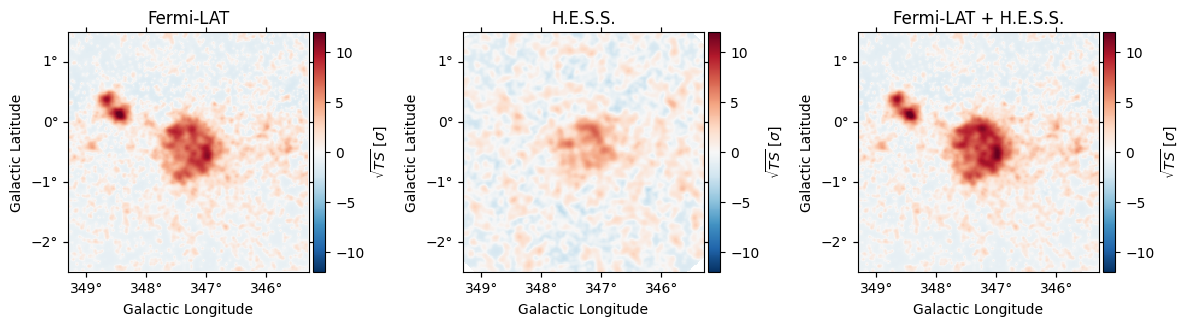

In [15]:
def plot_cutout(image, ax, plot_kwargs=None, margin=2*u.deg):
    image = image.cutout(
        image.geom.center_skydir, width=np.max(image.geom.width) - 2 * margin
    )
    kwargs = dict(ax=ax)
    if plot_kwargs : 
        kwargs.update(plot_kwargs)
    image.plot(**kwargs)

margin=2*u.deg
geom = datasets[0].counts.geom
fig_geom = geom.cutout(geom.center_skydir, width=np.max(geom.width) - 2 * margin)
resi_kwargs =dict(
        clim=[-12, 12],
        cmap=plt.cm.RdBu_r,
        add_cbar=True,
        kwargs_colorbar={"label": r"$\sqrt{TS}$ [$\sigma$]"},
    )

plt.figure(figsize=(12, 5))
ax1 = plt.subplot(131, projection=fig_geom.wcs)
plot_cutout(ts_results_fermi["sqrt_ts"], ax1, resi_kwargs)
ax1.set_title("Fermi-LAT")

ax2 = plt.subplot(132, projection=fig_geom.wcs)
plot_cutout(ts_results_hess["sqrt_ts"], ax2, resi_kwargs)
ax2.set_title("H.E.S.S.")

ax3 = plt.subplot(133, projection=fig_geom.wcs)
plot_cutout(ts_results_joint["sqrt_ts"], ax3, resi_kwargs)
ax3.set_title("Fermi-LAT + H.E.S.S.")

plt.tight_layout()

## Excess Maps

This use backward folding to estimate the TS and the flux in a given correlation radius.
In that case the predicted counts are the excess counts. The flux is the excess counts divided by the reconstructed exposure. So only the flux depends on the spectral model assumption not the TS.

In [16]:
estimator_rcorr0p1 = ExcessMapEstimator(correlation_radius="0.1 deg", spectral_model=spectral_model)

This will give use one estimation per dataset that we can combine together using `get_combined_significance_maps`.

The significance computation assumes that the model contains one degree of freedom per valid energy bin in each dataset.
This method implemented here is valid under the assumption that the TS in each independent bin follows a Chi2 distribution,
then the sum of the TS also follows a Chi2 distribution (with the sum of degree of freedom).

In [17]:
energy_axis = datasets[0].counts.geom.axes["energy"].squash()

In [18]:
energy_axis

MapAxis

	name       : energy    
	unit       : 'MeV'     
	nbins      : 1         
	node type  : edges     
	edges min  : 1.0e+04 MeV
	edges max  : 1.0e+06 MeV
	interp     : log

In [19]:
from gammapy.maps import MapAxis
energy_edges = [energy_axis.edges[0], energy_axis.edges[1]]
energy_axis2 = MapAxis.from_energy_edges(energy_edges)

In [20]:
energy_axis2

MapAxis

	name       : energy    
	unit       : 'MeV'     
	nbins      : 1         
	node type  : edges     
	edges min  : 1.0e+04 MeV
	edges max  : 1.0e+06 MeV
	interp     : log

In [21]:
spectral_model = PowerLawSpectralModel()
est = ExcessMapEstimator(correlation_radius="0.1 deg", spectral_model=spectral_model)
res  =est.run(datasets[0])

In [22]:
res.dnde

In [23]:
#get_combined_significance_maps?

In [24]:
%%time
results_combined_rcorr0p1 = get_combined_significance_maps(estimator_rcorr0p1, datasets)


Position <SkyCoord (ICRS): (ra, dec) in deg
    (255.02960205, -40.22290039)> is outside valid IRF map range, using nearest IRF defined within
Position <SkyCoord (ICRS): (ra, dec) in deg
    (255.02960205, -40.22290039)> is outside valid IRF map range, using nearest IRF defined within
Model 4FGL J1704.8-4030 is outside the target geom but contributes inside through the psf.This contribution cannot be estimated precisely.Consider extending the dataset geom and/or the masked margin in the mask_fit.
Model 4FGL J1705.2-3850 is outside the target geom but contributes inside through the psf.This contribution cannot be estimated precisely.Consider extending the dataset geom and/or the masked margin in the mask_fit.
Model 4FGL J1706.2-4113c is outside the target geom but contributes inside through the psf.This contribution cannot be estimated precisely.Consider extending the dataset geom and/or the masked margin in the mask_fit.
Model 4FGL J1706.5-4023c is outside the target geom but contribut

CPU times: user 3min 2s, sys: 12 s, total: 3min 14s
Wall time: 3min 26s


This approach is much faster than the TS map compuation but less precise in particular close to TS=0 where the validity of the hypostheses might break. However above few sigma this will point us toward the same excesses.

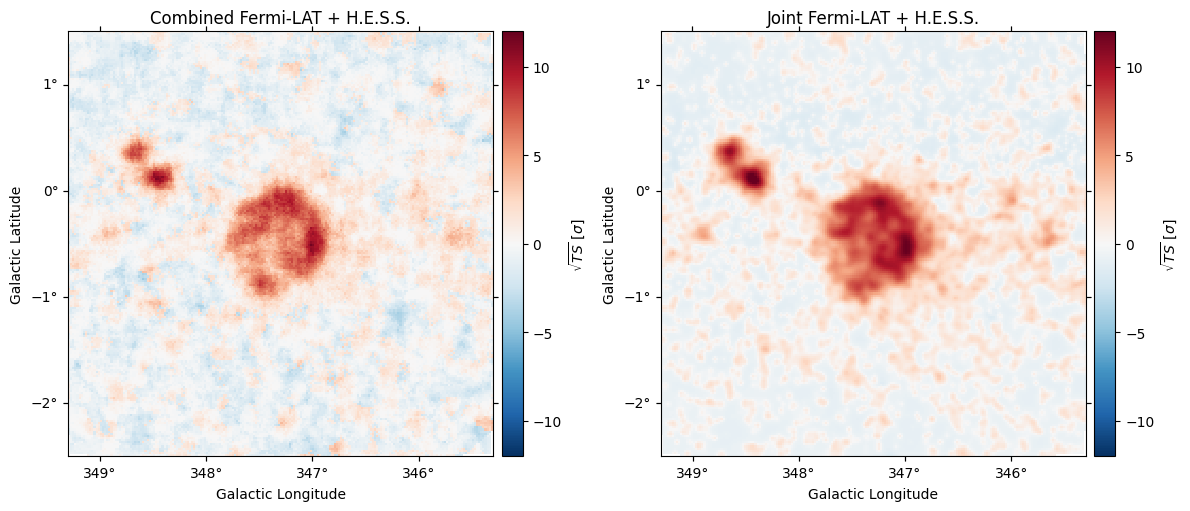

In [25]:
plt.figure(figsize=(12, 8))
ax1 = plt.subplot(121, projection=fig_geom.wcs)
plot_cutout(results_combined_rcorr0p1["significance"], ax1, resi_kwargs)
ax1.set_title("Combined Fermi-LAT + H.E.S.S.")

ax2 = plt.subplot(122, projection=fig_geom.wcs)
plot_cutout(ts_results_joint["sqrt_ts"], ax2, resi_kwargs)
ax2.set_title("Joint Fermi-LAT + H.E.S.S.")


plt.tight_layout()

As it is much faster we can test more model hypothesis in term of sizes

In [26]:
estimator_rcorr0p2 = ExcessMapEstimator(correlation_radius="0.2 deg", spectral_model=spectral_model)
results_combined_rcorr0p2 = get_combined_significance_maps(estimator_rcorr0p2, datasets)


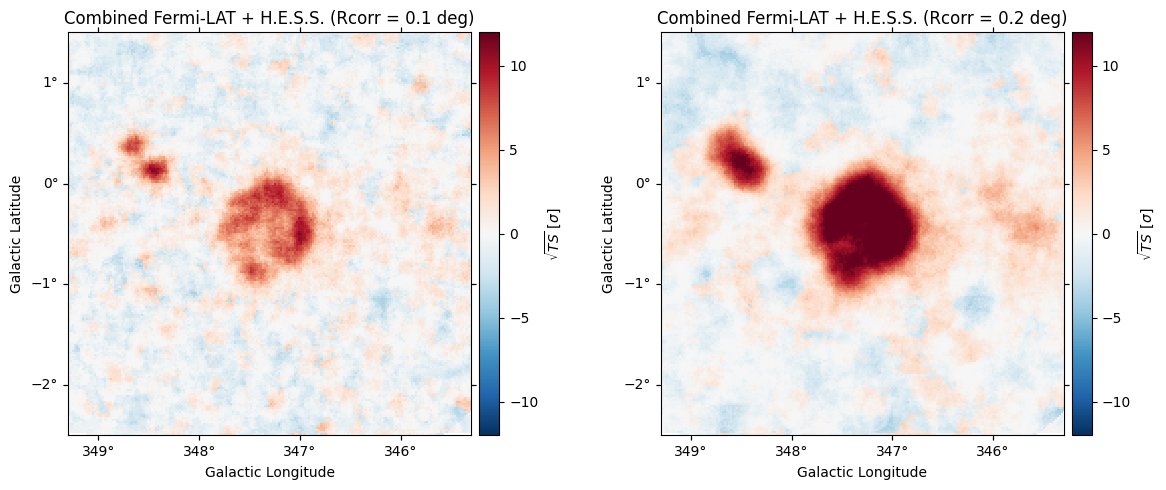

In [27]:
plt.figure(figsize=(12, 5))
ax1 = plt.subplot(121, projection=fig_geom.wcs)
plot_cutout(results_combined_rcorr0p1["significance"], ax1, resi_kwargs)
ax1.set_title("Combined Fermi-LAT + H.E.S.S. (Rcorr = 0.1 deg)")

ax2 = plt.subplot(122, projection=fig_geom.wcs)
plot_cutout(results_combined_rcorr0p2["significance"], ax2, resi_kwargs)
ax2.set_title("Combined Fermi-LAT + H.E.S.S. (Rcorr = 0.2 deg)")


plt.tight_layout()

Let's save one of the significance maps

In [29]:
results_combined_rcorr0p1["significance"].write("./datasets/rxj/maps/combined_significance_fermi_hess_rcorr0p1.fits.gz")

**In the next tutorial we will discuss, source detection techniques** 